# Проект "Прокат самокатов"

# Описание проекта
В этом проекте будет рассмотрены данные крупного сервиса проката самокатов GoFast. Компания предоставила три датасета с данными о пользователях сервиса, их поездках за один год, а также стоимости услуг в подписках.

# Цели и задачи проекта

Цель проекта - проанализировать демографию пользователей и особенности использования самокатов, а также определить возможную выгоду от распространения платной подписки на самокаты.

Задачи, поставленные в проекте:

- Загрузить и подготовить данные к анализу
- Описать и визуализировать общую информацию о пользователях и поездках
- Посчитать выручку за месяц по каждому пользователю
- Проверить ряд гипотез
- Смоделировать длительность поездки для генеральной совокупность и оценить долю длительных поездок

# Описание данных

Таблица с пользователями `users_go.csv`

- `user_id` — уникальный идентификатор пользователя.

- `name` — имя пользователя.

- `age` — возраст.

- `city` — город.

- `subscription_type` — тип подписки: `free`, `ultra`.

Таблица с поездками `rides_go.csv`

- `user_id` — уникальный идентификатор пользователя.

- `distance` — расстояние в метрах, которое пользователь проехал в текущей сессии.

- `duration` — продолжительность сессии в минутах, то есть время с того момента, как пользователь нажал кнопку «Начать поездку», до того, как он нажал кнопку «Завершить поездку».

- `date` — дата совершения поездки.

Таблица с подписками `subscriptions_go.csv`

- `subscription_type` — тип подписки.

- `minute_price` — стоимость одной минуты поездки по этой подписке.

- `start_ride_price` — стоимость начала поездки.

- `subscription_fee` — стоимость ежемесячного платежа.

# План работы

1. Загрузка и знакомство с данными
2. Предобработка данных
3. Исследовательский анализ данных
4. Объединение данных
5. Подсчёт выручки
6. Проверка гипотез
7. Обзор распределений

## 1. Загрузка и знакомство с данными
На первом этапе загрузим все необходимые данные и познакомимся с содержанием таблиц.

### 1.1 Импорт библиотек

In [2]:
# Импортируем библиотеки для анализа данных
import pandas as pd
import numpy as np

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

# Импортируем библиотеку для проверки гипотез
import scipy.stats as st

### 1.2 Чтение данных
Cчитаем и сохраним в отдельные датафреймы три CSV-файла.

In [3]:
df_users_go = pd.read_csv('https://code.s3.yandex.net/datasets/users_go.csv')
df_rides_go = pd.read_csv('https://code.s3.yandex.net/datasets/rides_go.csv')
df_subscriptions_go = pd.read_csv('https://code.s3.yandex.net/datasets/subscriptions_go.csv') 

### 1.3 Обзор данных
Познакомимся с содержанием таблиц.

Познакомимся с данными датасета `df_users_go` — выведем первые строки методом head(), а информацию о датафрейме методом info():

In [4]:
# Выводим первые строки датафрейма
df_users_go.head()

,user_id,name,age,city,subscription_type
0,1,Кира,22,Тюмень,ultra
1,2,Станислав,31,Омск,ultra
2,3,Алексей,20,Москва,ultra
3,4,Константин,26,Ростов-на-Дону,ultra
4,5,Адель,28,Омск,ultra


In [4]:
# Выводим информацию о датафрейме
df_users_go.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1565 entries, 0 to 1564
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   user_id            1565 non-null   int64 
 1   name               1565 non-null   object
 2   age                1565 non-null   int64 
 3   city               1565 non-null   object
 4   subscription_type  1565 non-null   object
dtypes: int64(2), object(3)
memory usage: 61.3+ KB


Познакомимся с данными датасета `df_rides_go` — выведем первые строки методом head(), а информацию о датафрейме методом info():

In [5]:
# Выводим первые строки датафрейма
df_rides_go.head()

,user_id,distance,duration,date
0,1,4409.919140,25.599769,2021-01-01
1,1,2617.592153,15.816871,2021-01-18
2,1,754.159807,6.232113,2021-04-20
3,1,2694.783254,18.511000,2021-08-11
4,1,4028.687306,26.265803,2021-08-28


In [6]:
# Выводим информацию о датафрейме
df_rides_go.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18068 entries, 0 to 18067
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   user_id   18068 non-null  int64  
 1   distance  18068 non-null  float64
 2   duration  18068 non-null  float64
 3   date      18068 non-null  object 
dtypes: float64(2), int64(1), object(1)
memory usage: 564.8+ KB


Познакомимся с данными датасета `df_subscriptions_go` — выведем первые строки методом head(), а информацию о датафрейме методом info():

In [7]:
# Выводим первые строки датафрейма
df_subscriptions_go.head()

,subscription_type,minute_price,start_ride_price,subscription_fee
0,free,8,50,0
1,ultra,6,0,199


In [8]:
# Выводим информацию о датафрейме
df_subscriptions_go.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   subscription_type  2 non-null      object
 1   minute_price       2 non-null      int64 
 2   start_ride_price   2 non-null      int64 
 3   subscription_fee   2 non-null      int64 
dtypes: int64(3), object(1)
memory usage: 196.0+ bytes


Определим количество строк в каждом из трех датафреймов. Это поможет оценить объем данных и выявить аномалии, например слишком малое количество записей.

In [9]:
print(df_users_go.shape[0], df_rides_go.shape[0], df_subscriptions_go.shape[0])

1565 18068 2


## 2. Предобработка данных

In [10]:
# Проверим типы данных
df_rides_go.dtypes

user_id       int64
distance    float64
duration    float64
date         object
dtype: object

In [11]:
# Приводим столбец date в датафрейме df_rides_go к типу даты pandas
df_rides_go['date'] = pd.to_datetime(df_rides_go['date'], errors='coerce')

In [12]:
# Создаем новый столбец с номером месяца
df_rides_go['month'] = df_rides_go['date'].dt.month

In [13]:
# Проверяем наличие пропусков и явных дубликатов в датафрейме df_users_go
na_count = df_users_go.isna().sum().sum()
dup_count = df_users_go.duplicated().sum()
print(na_count, dup_count)

0 31


In [14]:
# Проверяем наличие пропусков и явных дубликатов в датафрейме df_rides_go
na_count_r = df_rides_go.isna().sum().sum()
dup_count_r = df_rides_go.duplicated().sum()
print(na_count_r, dup_count_r)

0 0


In [15]:
# Проверяем наличие явных дубликатов в датафрейме df_rides_go по нескольким столбцам
df_rides_go.duplicated(subset=['distance', 'duration']).sum()

np.int64(0)

In [16]:
# Удалим дубликаты в датафрейме df_users_go
df_users_go.drop_duplicates(keep='first', inplace=True)

In [17]:
# Округлим время поездки duration до целого числа
df_rides_go['duration'] = df_rides_go['duration'].round()
df_rides_go['duration'] = df_rides_go['duration'].astype(int)

## 3. Исследовательский анализ данных

### 3.1 Количество пользователей по городам
Изучим количество пользователей в каждом из городов.

In [18]:
# Подсчет частоты
users_by_city_count = df_users_go['city'].value_counts()
display(users_by_city_count)

city
Пятигорск         219
Екатеринбург      204
Ростов-на-Дону    198
Краснодар         193
Сочи              189
Омск              183
Тюмень            180
Москва            168
Name: count, dtype: int64

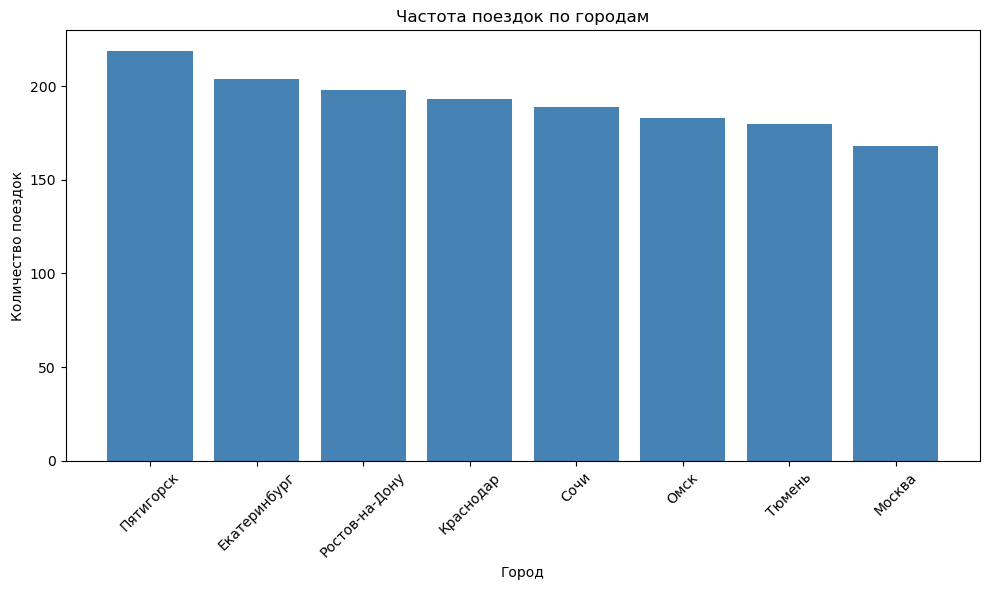

In [19]:
# Построение графика
plt.figure(figsize=(10, 6))
plt.bar(users_by_city_count.index, users_by_city_count.values, color='steelblue')
plt.xlabel('Город')
plt.ylabel('Количество поездок')
plt.title('Частота поездок по городам')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Город-курорт Пятигорск оказался лидером по числу пользователей самокатов, а вот Москва в хвосте.

### 3.2 Количество пользователей подписки
Рассмотрим количество пользователей для каждого типа подписки `subscription_type`.

In [20]:
# Подсчет соотношения
subscription_type_count = df_users_go['subscription_type'].value_counts()
display(subscription_type_count)

subscription_type
free     835
ultra    699
Name: count, dtype: int64

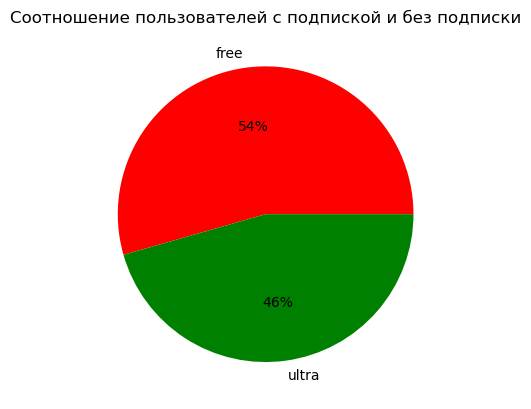

In [21]:
# Построение графика
subscription_type_count.plot(
    kind='pie',
    title='Соотношение пользователей с подпиской и без подписки',
    autopct='%.0f%%',
    ylabel='',
    colors=['red', 'green']
)
plt.show()

Подписчиков сервиса всё же несколько меньше, чем пользователей без подписки. Достоверно сказать, плохо это или хорошо, мы пока не можем, так что примем за факт.

### 3.3 Гистограмма возрастов
Построим гистограмму возрастов `age` пользователей самокатов. Используем количество бинов, равное разности максимального и минимального значений возраста.

In [22]:
# Распределение возраста
df_users_go['age'].describe()

count    1534.000000
mean       24.903520
std         4.572367
min        12.000000
25%        22.000000
50%        25.000000
75%        28.000000
max        43.000000
Name: age, dtype: float64

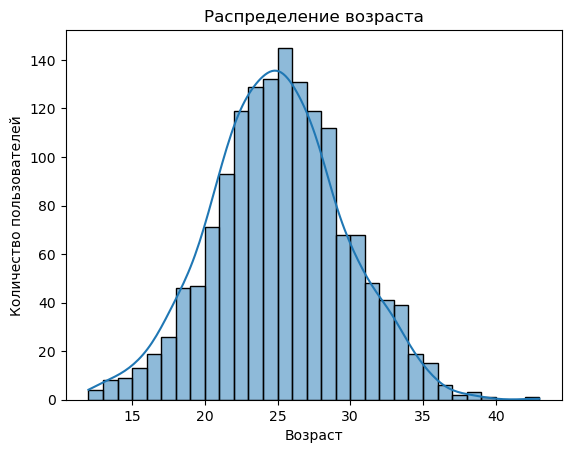

In [23]:
# Построение гистограммы
n_bins = df_users_go['age'].max() - df_users_go['age'].min()
sns.histplot(data=df_users_go, x='age', bins=n_bins, kde=True)
plt.title('Распределение возраста')
plt.xlabel('Возраст')
plt.ylabel('Количество пользователей')
plt.show()

Напоминает нормальное распределение.

При этом части пользователей еще не исполнилось 18 лет. Нужно будет внимательнее изучить эту группу.

### 3.4 Несовершеннолетние пользователи
Рассчитаем долю несовершеннолетних (возрастом менее 18 лет) пользователей самокатов.

In [24]:
count_under_18 = (df_users_go['age'] < 18).sum()
total_users = len(df_users_go)
users_under_18_ratio = round((count_under_18 / total_users) * 100)
print(f'Доля несовершеннолетних пользователей самокатов составляет {users_under_18_ratio}%.')

Доля несовершеннолетних пользователей самокатов составляет 5%.


Доля несовершеннолетних пользователей оказалась 5%. Такие клиенты — важная часть жизни сервиса. Если человек с ранних лет пользуется самокатами, то вполне возможно, что он сохранит лояльность сервису ещё на долгие годы.

### 3.7 Характеристики длительности поездки
Длительность поездки является важной метрикой в работе сервиса проката самокатов. Если средняя длительность поездок будет слишком высокой, самокаты будут быстрее выходить из строя. Если слишком низкой, значит, клиентам что-то не нравится в сервисе.

Cформулируем и выведем текстовый вывод о средней длительности поездки, а также о 25-м и 75-м процентилях длительности.

In [25]:
# Распределение расстояния
duration_mean = round(df_rides_go['duration'].mean())
duration_std = round(df_rides_go['duration'].std())

duration_pct25 = round(df_rides_go['duration'].quantile(0.25))
duration_pct75 = round(df_rides_go['duration'].quantile(0.75))

print(f'Средняя длительность поездки {duration_mean} минут со стандартным отклонением {duration_std}. Основная часть поездок занимает от {duration_pct25} до {duration_pct75} минут.')

Средняя длительность поездки 18 минут со стандартным отклонением 6. Основная часть поездок занимает от 14 до 22 минут.


На сервисе почти нет долгих поездок, и это хорошо. Так самокаты будут меньше изнашиваться и меньше нуждаться в ремонте.

Визуализируем распределение продолжительности поездок.

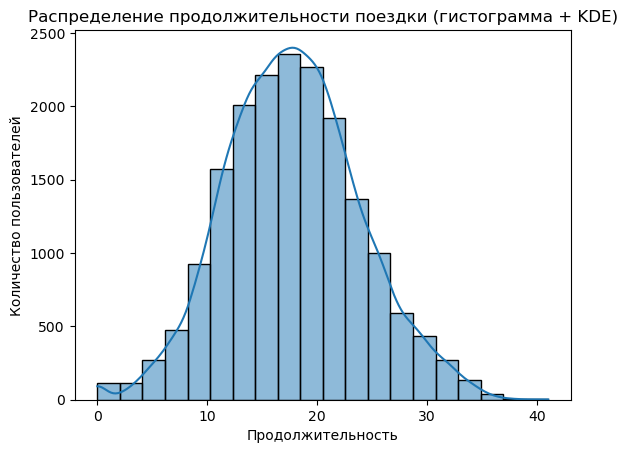

In [26]:
# Построение гистограммы
sns.histplot(data=df_rides_go, x='duration', bins=20, kde=True)
plt.title('Распределение продолжительности поездки (гистограмма + KDE)')
plt.xlabel('Продолжительность')
plt.ylabel('Количество пользователей')
plt.show()

## 4. Объединение данных
### 4.1 Объединение таблиц пользователей, поездок и подписок

Объединим датафреймы с информацией о пользователях `df_users_go` и поездках `df_rides_go`.

In [27]:
# Объединяем пользователей и поездки по user_id
df = pd.merge(df_users_go, df_rides_go, on='user_id', how='left')

Присоедините к полученному датафрейму `df` информацию о подписках из `df_subscriptions_go`.

In [28]:
# Присоединяем данные о подписках по типу подписки
df = pd.merge(df, df_subscriptions_go, on='subscription_type', how='left')

### 4.2 Размеры объединённого датафрейма

Для финальной проверки выведем на экран первые пять строк датафрейма, а также количество строк и столбцов полученного датафрейма `df`. Этот этап позволит убедиться, что никакие записи не потерялись при объединении.

In [29]:
# Выводим первые строки датафрейма
display(df.head())

# Выводим количество строк и столбцов в объединённом датафрейме
n_rows, n_cols = df.shape
print(f'В полученном датафрейме {n_rows} строк и {n_cols} столбцов.')

,user_id,name,age,city,subscription_type,distance,duration,date,month,minute_price,start_ride_price,subscription_fee
0,1,Кира,22,Тюмень,ultra,4409.919140,26,2021-01-01,1,6,0,199
1,1,Кира,22,Тюмень,ultra,2617.592153,16,2021-01-18,1,6,0,199
2,1,Кира,22,Тюмень,ultra,754.159807,6,2021-04-20,4,6,0,199
3,1,Кира,22,Тюмень,ultra,2694.783254,19,2021-08-11,8,6,0,199
4,1,Кира,22,Тюмень,ultra,4028.687306,26,2021-08-28,8,6,0,199


В полученном датафрейме 18068 строк и 12 столбцов.


Любой «джойн» требует проверки. К счастью, всё в порядке, и данные не потерялись.

### 4.3 Отдельные датафреймы для пользователей с подпиской и без
Создадим два вспомогательных датафрейма на основе `df`: первый только для пользователей с подпиской `df_ultra` и второй только для пользователей без подписки `df_free`.

In [30]:
# Датафрейм с пользователями без подписки (free)
df_free = df[df['subscription_type'] == 'free']

# Датафрейм с пользователями подписки ultra
df_ultra = df[df['subscription_type'] == 'ultra']

### 4.4 Гистограмма длительности поездок для обоих групп
На одном графике постройте гистограмму распределения длительности поездок `duration` для пользователей с подпиской и без.

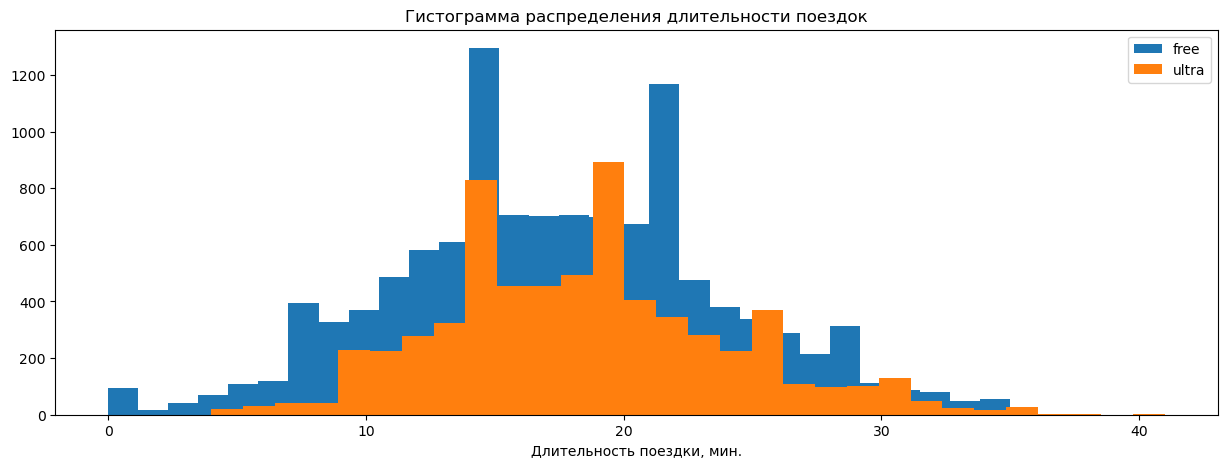

Средняя длительность поездки для пользователей без подписки 17 мин, а для пользователей с подпиской 19 мин


In [31]:
# Гистограмма длительности поездки для пользователей с подпиской и без
plt.figure(figsize=(15, 5))
plt.hist(df_free['duration'], bins=30, label='free')
plt.hist(df_ultra['duration'], bins=30, label='ultra')
plt.xlabel('Длительность поездки, мин.')
plt.title('Гистограмма распределения длительности поездок')
plt.legend()
plt.show()

# Расчет и вывод на экран средней длительности поездки для пользователей с подпиской и без
mean_duration_free = round(df_free['duration'].mean())
mean_duration_ultra = round(df_ultra['duration'].mean())
print(f'Средняя длительность поездки для пользователей без подписки {mean_duration_free} мин, а для пользователей с подпиской {mean_duration_ultra} мин')

На графике видно, что профили длительности поездок у пользователей с разной подпиской схожи. У пользователей без платной подписки больший разброс по времени поездок, чем у пользователей с платной подпиской Ultra.

## 5. Подсчёт выручки
Данные о количестве и длительности поездок объединены с ценами и тарифами, а значит, теперь есть всё необходимое, чтобы рассчитать важный для бизнеса показатель — выручку.

### 5.1 Данные сгруппированные по нужным колонкам
Сгруппируем данные по следующим столбцам: `user_id`, `name`, `subscription_type`, `month`. Группировку произведем в датафрейме `df_gp`.

In [32]:
# Группируем
df_gp = df.groupby(['user_id', 'name', 'subscription_type', 'month'], as_index=False)

### 5.2 Подсчёт агрегированных метрик
Создадим новый датафрейм `df_agg`. В нём для каждой группы рассчитаем и добавим в датафрейм следующие агрегированные значения, используя метод `agg()`:
- `total_distance` — сумма значений в столбце `distance`.
- `total_duration` — сумма значений в столбце `duration`.
- `rides_count` — количество элементов в столбце `duration`.
- `subscription_type` — первое значение в группе для столбца `subscription_type`.
- `minute_price` — первое значение в группе для столбца `minute_price`.
- `start_ride_price` — первое значение в группе для столбца `start_ride_price`.
- `subscription_fee` — первое значение в группе для столбца `subscription_fee`.

In [33]:
# Создаем датафрейм с агрегированными значениями
df_agg = df_gp.agg(
    total_distance=('distance', 'sum'),
    total_duration=('duration', 'sum'),
    rides_count=('duration', 'count'),
    subscription_type=('subscription_type', 'first'),
    minute_price=('minute_price', 'first'),
    start_ride_price=('start_ride_price', 'first'),
    subscription_fee=('subscription_fee', 'first')
)

### 5.3 Функция для подсчёта выручки
Создадим функцию `calculate_monthly_revenue(row)` для расчёта месячной выручки по формуле:

`monthly_revenue` = `start_ride_price` * `rides_count` + `minute_price` * `total_duration` + `subscription_fee`

В качестве входных данных функция будет принимать одну строку `row` датафрейма.

Здесь:
- `start_ride_price * rides_count` — выручка от начала каждой поездки.
- `minute_price * total_duration` — выручка за время использования.
- `subscription_fee` — фиксированная выручка от подписок.

In [34]:
def calculate_monthly_revenue(row):
    return (row['start_ride_price'] * row['rides_count'] + 
            row['minute_price'] * row['total_duration'] + 
            row['subscription_fee'])

### 5.4 Создание столбца с месячной выручкой на пользователя
Создадим новый столбец с месячной выручкой на пользователя `monthly_revenue`. Для этого применим функцию `calculate_monthly_revenue(row)` к каждой строке агрегированного датафрейма `df_agg`.

In [35]:
df_agg['monthly_revenue'] = df_agg.apply(calculate_monthly_revenue, axis=1)

### 5.5 Поиск пользователя с максимальной выручкой
Исследуем полученные значения выручки. Найдем пользователя с максимальной суммарной выручкой за весь период наблюдения и для него выведем на экран `user_id`, имя, месяц, количество поездок и выручку за каждый из месяцев.

In [36]:
# Считаем суммарную выручку по каждому пользователю за весь период
total_revenue_by_user = df_agg.groupby('user_id')['monthly_revenue'].sum()

# Находим id пользователя с максимальной суммарной выручкой
top_user_id = total_revenue_by_user.idxmax()

# Выводим данные по этому пользователю за каждый месяц
result = df_agg[df_agg['user_id'] == top_user_id][['user_id', 'name', 'month', 'rides_count', 'monthly_revenue']]

result

,user_id,name,month,rides_count,monthly_revenue
8877,1236,Александр,1,2,228
8878,1236,Александр,2,3,614
8879,1236,Александр,3,5,762
8880,1236,Александр,4,1,202
8881,1236,Александр,5,3,574
8882,1236,Александр,6,1,282
8883,1236,Александр,7,1,290
8884,1236,Александр,8,2,452
8885,1236,Александр,9,1,122
8886,1236,Александр,10,3,430


Видно, что пользователь под номером 1236 приносит самую большую выручку.

## 6. Проверка гипотез

### 6.1 Вспомогательная функция для интерпретации результатов
Напишем вспомогательную функцию `print_stattest_results(p_value, alpha)`, которая будет интерпретировать результаты статистического теста на основе p-value и заданного уровня значимости (α-уровня). Функция должна решать, следует ли принять альтернативную гипотезу или сохранить нулевую гипотезу.

У функции два параметра:
- `p_value` (тип `float`) — значение p-value, полученное в результате выполнения статистического теста.
- `alpha` (тип `float`, необязательный, по умолчанию `alpha = 0.05`) — уровень значимости статистического теста, который используется как порог для принятия решения об отклонении нулевой гипотезы.

Если мы принимаем альтернативную гипотезу, нужно вывести сообщение:
`'Полученное значение p_value=<Введённое значение p_value> меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.'`

Если вы не можем опровергнуть нулевую гипотезу, нужно вывести сообщение: `'Полученное значение p_value=<Введённое значение p_value> больше критического уровня alpha=0.05. Опровергнуть нулевую гипотезу нельзя.'`

Попробуем вызвать функцию для `p_value = 0.0001` и `p_value = 0.1`.

In [37]:
def print_stattest_results(p_value: float, alpha: float = 0.05):
    if p_value < alpha:
        print(f"Полученное значение p_value={p_value} меньше критического уровня alpha={alpha}. Принимаем альтернативную гипотезу.")
    else:
        print(f"Полученное значение p_value={p_value} больше критического уровня alpha={alpha}. Опровергнуть нулевую гипотезу нельзя.")

print_stattest_results(p_value=0.0001)
print_stattest_results(p_value=0.1)

Полученное значение p_value=0.0001 меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.
Полученное значение p_value=0.1 больше критического уровня alpha=0.05. Опровергнуть нулевую гипотезу нельзя.


### 6.2 Длительность для пользователей с подпиской и без

Важно понять, тратят ли пользователи с подпиской больше времени на поездки? Сформулируем нулевую и альтернативную гипотезы:
- Нулевая гипотеза (Н0): Среднее время поездки у пользователей с подпиской и без подписки одинаковое.
- Альтернативная гипотеза (Н1): Среднее время поездки у пользователей с подпиской больше, чем у пользователей без подписки.

In [38]:
ultra_duration = df_ultra['duration']
free_duration = df_free['duration']

results = st.ttest_ind(ultra_duration, free_duration, alternative='greater')
p_value = results.pvalue
print_stattest_results(p_value)

ultra_mean_duration = round(df_ultra['duration'].mean(), 2)
free_mean_duration = round(df_free['duration'].mean(), 2)

print(f'Средняя длительность поездки тарифа Ultra {ultra_mean_duration}')
print(f'Средняя длительность поездки тарифа Free {free_mean_duration}')

Полученное значение p_value=3.1600689435611813e-35 меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.
Средняя длительность поездки тарифа Ultra 18.55
Средняя длительность поездки тарифа Free 17.39


Мы проверили первую гипотезу с использованием t-теста. Оказалось, что пользователи тарифа Ultra действительно статистически значимо имеют большую длительность поездки с уровнем значимости 0.05.

### 6.3 Длительность поездки: больше или меньше критического значения

Проанализируем ещё одну важную продуктовую гипотезу. Расстояние одной поездки в 3130 метров — оптимальное с точки зрения износа самоката. Можно ли сказать, что расстояние, которое проезжают пользователи с подпиской за одну поездку, меньше 3130 метров?

Сформулируем нулевую и альтернативную гипотезы:

- Нулевая гипотеза (Н0): Средняя дистанция поездки у пользователей с подпиской равна 3130 м.

- Альтернативная гипотеза (Н1): Средняя дистанция поездки у пользователей с подпиской больше 3130 м.

In [39]:
null_hypothesis = 3130
ultra_distance = df_ultra['distance']

results = st.ttest_1samp(ultra_distance, null_hypothesis, alternative='greater')
p_value = results.pvalue
print_stattest_results(p_value)

Полученное значение p_value=0.9195368847849785 больше критического уровня alpha=0.05. Опровергнуть нулевую гипотезу нельзя.


Такой тест позволил проверить равенство выборочного среднего определённому значению. В этом случае не удалось опровергнуть нулевую гипотезу, значит, есть основания утверждать, что подписчики проезжают расстояние в пределах заданного.

### 6.4 Прибыль от пользователей с подпиской и без
Проверем гипотезу о том, что выручка от пользователей с подпиской выше, чем выручка от пользователей без подписки.

Сформулируем нулевую и альтернативную гипотезы:

- Нулевая гипотеза (Н0): Средняя месячная выручка у пользователей с подпиской и без подписки одинаковая.
- Альтернативная гипотеза (Н1): Средняя месячная выручка у пользователей с подпиской выше, чем у пользователей без подписки.

In [40]:
revenue_ultra = df_agg[df_agg['subscription_type'] == 'ultra']['monthly_revenue']
revenue_free = df_agg[df_agg['subscription_type'] == 'free']['monthly_revenue']

results = st.ttest_ind(revenue_ultra, revenue_free, alternative='greater')
p_value = results.pvalue
print_stattest_results(p_value)

mean_revenue_ultra = round(revenue_ultra.mean())
mean_revenue_free = round(revenue_free.mean())

print(f'Средняя выручка подписчиков Ultra {mean_revenue_ultra} руб')
print(f'Средняя выручка подписчиков Free {mean_revenue_free} руб')

Полученное значение p_value=1.7274069878387966e-37 меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.
Средняя выручка подписчиков Ultra 359 руб
Средняя выручка подписчиков Free 322 руб


Действительно, средняя выручка от пользователя с подпиской оказалась выше на 37 руб.

## 7. Обзор распределений

В компании возникла идея предлагать дополнительную скидку подписчикам, совершающим длительные поездки продолжительностью более 30 минут. Необходимо оценить долю таких поездок.

В одном из предыдущих заданий мы уже построили гистограмму распределения длительности поездок для выборки. Однако эти данные охватывают лишь часть пользователей всех самокатов, а нас интересуют возможные значения для всей генеральной совокупности. Учитывая, что у нас нет доступа ко всем данным о поездках, было решено смоделировать длительность поездки с помощью нормального распределения, используя в качестве параметров выборочное среднее и стандартное отклонение из доступных данных о поездках.

### 7.1 Расчёт выборочного среднего и стандартного отклонения

In [41]:
# Вычисляем среднее значение
mu = df_ultra['duration'].mean()

# Вычисляем стандартное отклонение
sigma = df_ultra['duration'].std()

# Задаём целевое время
target_time = 30

# Делаем вывод
print(f'Средняя длительность поездки {round(mu, 1)}, стандартное отклонение {round(sigma, 1)}.')

Средняя длительность поездки 18.5, стандартное отклонение 5.6.


### 7.2 Вычисление значения функции распределения в точке (CDF)
Если вычислить значение функции распределения в точке, это позволит узнать вероятность того, что случайная величина примет значение меньше заданного либо равное ему. Соответственно, если мы хотим ответить на вопрос о вероятности поездки более 30 минут, потребуется использовать CDF.

In [42]:
# Вычисляем вероятность того, что случайная величина будет меньше указанного значения или равна ему
duration_norm_dist = st.norm(mu, sigma)
cdf_val = duration_norm_dist.cdf(target_time)
prob = round(1 - cdf_val, 3)

print(f'Вероятность поездки более 30 минут {prob}')

Вероятность поездки более 30 минут 0.02


Процент таких пользователей не высок.

### 7.3 Вероятность для интервала (CDF)
Процент пользователей, для которых будет показана скидка, недостаточно большой и вряд ли поможет в увеличении лояльности клиентов. Стоит проверить, какой процент пользователей совершает поездки в интервале от 20 до 30 минут. Возможно, именно для них стоит провести промоакцию.

In [43]:
# Определяем границы интервала
low = 20
high = 30

# Вычисляем вероятность попадания в интервал
cdf_low = duration_norm_dist.cdf(low)
cdf_high = duration_norm_dist.cdf(high)
prob_interval = round(cdf_high - cdf_low, 3)

# Выводим результат
print(f'Вероятность того, что пользователь совершит поездку длительностью от {low} до {high} минут: {prob_interval}')

Вероятность того, что пользователь совершит поездку длительностью от 20 до 30 минут: 0.377


Процент таких пользователей значительно больше. Вполне возможно, что промоакция на такой выборке поможет вырастить лояльность продукту.

### 7.4 Определение критической дистанции поездок (PPF)
Длительные поездки могут негативно сказываться на сроке службы самоката. В связи с этим нужно установить критическую дистанцию, превышение которой будет сопровождаться дополнительной платой. Для этого необходимо определить расстояние, которое превышается только в 10% поездок (90-й процентиль).

Необходимо смоделировать распределение длительности поездок, предполагая, что оно подчиняется нормальному закону, и рассчитать критическую дистанцию, ниже которой находится 90% всех поездок.

In [44]:
# Вычисляем среднее значение
mu = df['distance'].mean()

# Вычисляем стандартное отклонение
sigma = df['distance'].std()

# Вероятность, для которой хотим найти значение (90% случаев)
target_prob = 0.90

# Создаём объект нормального распределения
distance_norm = st.norm(mu, sigma)

# Рассчитываем критическую дистанцию для заданного процентиля поездок
critical_distance = distance_norm.ppf(target_prob)

print(f'{100 * target_prob} % поездок имеют дистанцию ниже критического значения {critical_distance:.2f} М.')

90.0 % поездок имеют дистанцию ниже критического значения 4501.94 М.


Теперь мы знаем это значение. Введение дополнительных сборов за длинные поездки снизит эксплуатационные издержки и повысит прибыльность.